In [59]:
# Import matplotlib
import matplotlib.pyplot as plt
# Import pandas for data manipulation
import pandas as pd

In [60]:
# Load the Telco Customer Churn dataset
df = pd.read_csv("Telco-Customer-Churn.csv")

# Display the first 5 rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [61]:
# Check the number of rows and columns in the dataset
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 7043
Number of columns: 21


In [62]:
# Display all column names and their data types
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [63]:
# Check the number of missing values in each column
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [64]:
# Count the number of customers in each churn category
df["Churn"].value_counts()

No     5174
Yes    1869
Name: Churn, dtype: int64

In [65]:
# Check for blank or whitespace-only values in TotalCharges
blank_total_charges = df["TotalCharges"].str.strip().eq("").sum()

print("Blank values in TotalCharges:", blank_total_charges)

Blank values in TotalCharges: 11


In [66]:
# Convert TotalCharges from object to numeric
# Invalid or blank values will be converted to NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Count missing values after conversion
print("Missing values in TotalCharges:", df["TotalCharges"].isnull().sum())

# Check the data type
print("Data type of TotalCharges:", df["TotalCharges"].dtype)

Missing values in TotalCharges: 11
Data type of TotalCharges: float64


In [67]:
# Remove rows where TotalCharges is missing
df.dropna(subset=["TotalCharges"], inplace=True)

# Check the new dataset dimensions
print("Dataset shape after cleaning:", df.shape)

# Confirm missing values have been removed
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

Dataset shape after cleaning: (7032, 21)
Missing TotalCharges: 0


In [68]:
# Generate descriptive statistics for numerical columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000,7032.000000,7032.000000
mean,0.162400,32.421786,64.798208,2283.300441
std,0.368844,24.545260,30.085974,2266.771362
min,0.000000,1.000000,18.250000,18.800000
25%,0.000000,9.000000,35.587500,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.862500,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [69]:
# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check for duplicate customer IDs
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


#  Visualize customer churn distribution

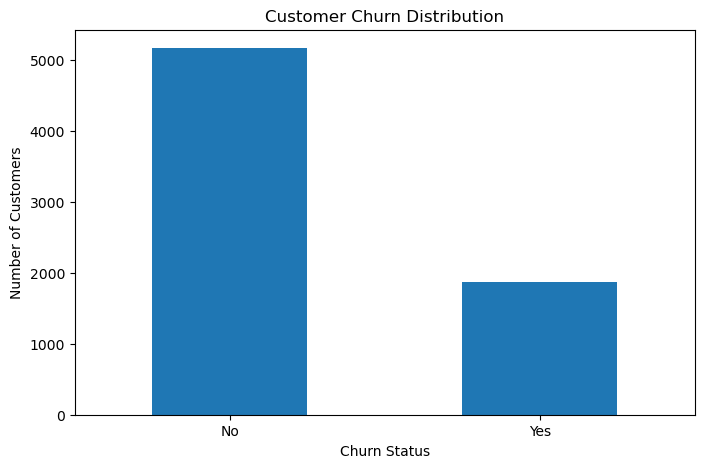

In [70]:
# Count customers in each churn category
churn_counts = df["Churn"].value_counts()

# Create a bar chart
plt.figure(figsize=(8, 5))
churn_counts.plot(kind="bar")

# Add chart title and labels
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

# Display the chart
plt.show()

#  Analyze churn by contract type

In [71]:
# Calculate churn counts by contract type
contract_churn = pd.crosstab(df["Contract"], df["Churn"])

# Display the results
contract_churn

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1306,166
Two year,1637,48


# Analyze churn by Internet Service

In [72]:
# Calculate churn counts by Internet Service
internet_churn = pd.crosstab(df["InternetService"], df["Churn"])

# Display the results
internet_churn

Churn,No,Yes
InternetService,,
DSL,1957,459
Fiber optic,1799,1297
No,1407,113


#  Analyze churn by payment method

In [73]:
# Calculate churn counts by payment method
payment_churn = pd.crosstab(df["PaymentMethod"], df["Churn"])

# Display the results
payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1284,258
Credit card (automatic),1289,232
Electronic check,1294,1071
Mailed check,1296,308


# Analyze churn by customer tenure

In [74]:
# Group customers by churn status and calculate tenure statistics
df.groupby("Churn")["tenure"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5163.0,37.650010,24.076940,1.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


# Step 16: Visualize customer tenure by churn status

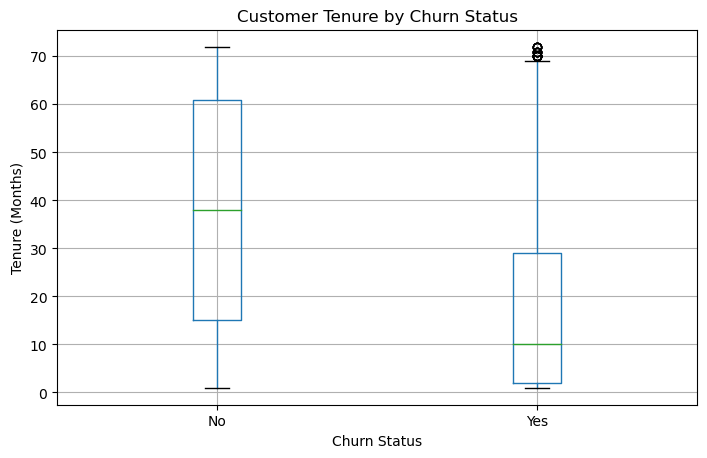

In [75]:
# Import matplotlib
import matplotlib.pyplot as plt

# Create a boxplot of tenure by churn status
df.boxplot(column="tenure", by="Churn", figsize=(8, 5))

# Add title and axis labels
plt.title("Customer Tenure by Churn Status")
plt.suptitle("")  # Remove automatic subtitle
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")

# Display the plot
plt.show()

# Step 17: Analyze monthly charges by churn status

In [76]:
# Compare monthly charges for customers who stayed and churned
df.groupby("Churn")["MonthlyCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5163.0,61.307408,31.094557,18.25,25.10,64.45,88.475,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.65,94.200,118.35


# Step 18: Visualize monthly charges by churn status

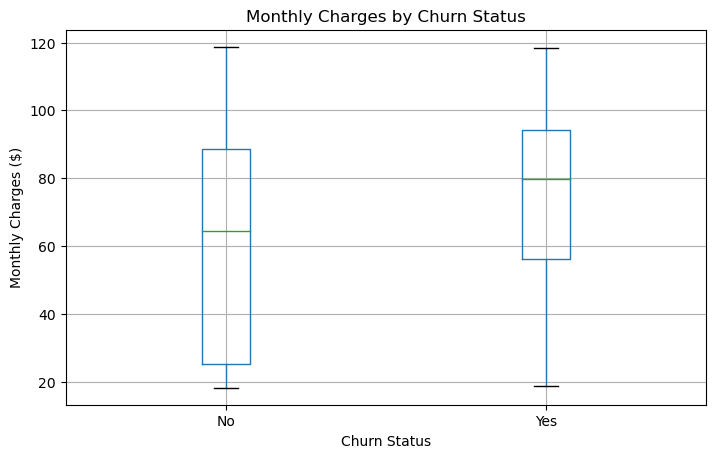

In [77]:
# Create a boxplot comparing monthly charges by churn status
df.boxplot(column="MonthlyCharges", by="Churn", figsize=(8, 5))

# Add chart title and labels
plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges ($)")

# Display the plot
plt.show()

#  Analyze total charges by churn status

In [78]:
# Compare total charges for customers who stayed and churned
df.groupby("Churn")["TotalCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5163.0,2555.344141,2329.456984,18.80,577.825,1683.60,4264.125,8672.45
Yes,1869.0,1531.796094,1890.822994,18.85,134.500,703.55,2331.300,8684.80


#  Analyze correlations among numerical features

In [79]:
# Calculate the correlation matrix for numerical variables
correlation_matrix = df[
    ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
].corr()

# Display the correlation matrix
correlation_matrix

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000000,0.015683,0.219874,0.102411
tenure,0.015683,1.000000,0.246862,0.825880
MonthlyCharges,0.219874,0.246862,1.000000,0.651065
TotalCharges,0.102411,0.825880,0.651065,1.000000


#  Visualize the correlation matrix

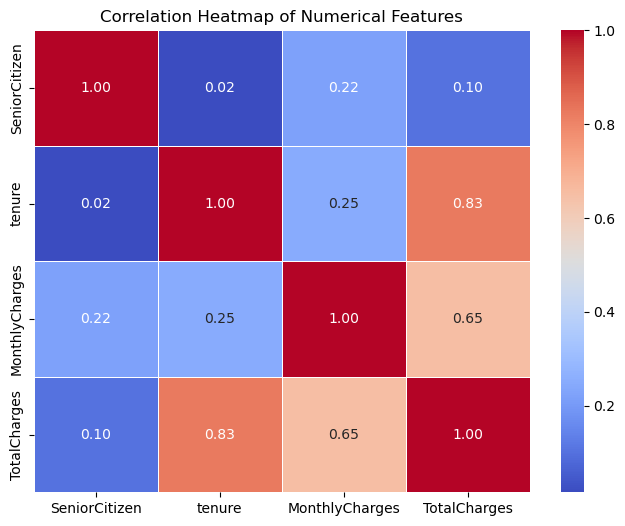

In [80]:
# Import seaborn for heatmap visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Create the correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

# Add chart title
plt.title("Correlation Heatmap of Numerical Features")

# Display the plot
plt.show()

#  Analyze churn by gender

In [81]:
# Calculate churn counts by gender
gender_churn = pd.crosstab(df["gender"], df["Churn"])

# Display the results
gender_churn

Churn,No,Yes
gender,,
Female,2544,939
Male,2619,930


#  Analyze churn by Senior Citizen status

In [82]:
# Calculate churn counts by SeniorCitizen status
senior_churn = pd.crosstab(df["SeniorCitizen"], df["Churn"])

# Display the results
senior_churn

Churn,No,Yes
SeniorCitizen,,
0,4497,1393
1,666,476


#  Analyze churn by Partner status

In [83]:
# Calculate churn counts by Partner status
partner_churn = pd.crosstab(df["Partner"], df["Churn"])

# Display the results
partner_churn

Churn,No,Yes
Partner,,
No,2439,1200
Yes,2724,669


# Analyze churn by Dependents status

In [84]:
# Calculate churn counts by Dependents status
dependents_churn = pd.crosstab(df["Dependents"], df["Churn"])

# Display the results
dependents_churn

Churn,No,Yes
Dependents,,
No,3390,1543
Yes,1773,326


#  Analyze churn by Phone Service

In [85]:
# Calculate churn counts by PhoneService
phone_churn = pd.crosstab(df["PhoneService"], df["Churn"])

# Display the results
phone_churn

Churn,No,Yes
PhoneService,,
No,510,170
Yes,4653,1699


#  Analyze churn by Paperless Billing

In [86]:
# Calculate churn counts by PaperlessBilling
paperless_churn = pd.crosstab(df["PaperlessBilling"], df["Churn"])

# Display the results
paperless_churn

Churn,No,Yes
PaperlessBilling,,
No,2395,469
Yes,2768,1400


#  Analyze churn by Online Security

In [87]:
# Calculate churn counts by OnlineSecurity
security_churn = pd.crosstab(df["OnlineSecurity"], df["Churn"])

# Display the results
security_churn

Churn,No,Yes
OnlineSecurity,,
No,2036,1461
No internet service,1407,113
Yes,1720,295


#  Analyze churn by Online Backup

In [88]:
# Calculate churn counts by OnlineBackup
backup_churn = pd.crosstab(df["OnlineBackup"], df["Churn"])

# Display the results
backup_churn

Churn,No,Yes
OnlineBackup,,
No,1854,1233
No internet service,1407,113
Yes,1902,523


#  Analyze churn by Device Protection

In [89]:
# Calculate churn counts by DeviceProtection
device_churn = pd.crosstab(df["DeviceProtection"], df["Churn"])

# Display the results
device_churn

Churn,No,Yes
DeviceProtection,,
No,1883,1211
No internet service,1407,113
Yes,1873,545


#  Analyze churn by Tech Support

In [90]:
# Calculate churn counts by TechSupport
techsupport_churn = pd.crosstab(df["TechSupport"], df["Churn"])

# Display the results
techsupport_churn

Churn,No,Yes
TechSupport,,
No,2026,1446
No internet service,1407,113
Yes,1730,310


#  Analyze churn by Streaming TV

In [91]:
# Calculate churn counts by StreamingTV
streamingtv_churn = pd.crosstab(df["StreamingTV"], df["Churn"])

# Display the results
streamingtv_churn

Churn,No,Yes
StreamingTV,,
No,1867,942
No internet service,1407,113
Yes,1889,814


#  Analyze churn by Streaming Movies

In [92]:
# Calculate churn counts by StreamingMovies
streamingmovies_churn = pd.crosstab(df["StreamingMovies"], df["Churn"])

# Display the results
streamingmovies_churn

Churn,No,Yes
StreamingMovies,,
No,1843,938
No internet service,1407,113
Yes,1913,818


#  Analyze churn by Multiple Lines

In [93]:
# Calculate churn counts by MultipleLines
multiplelines_churn = pd.crosstab(df["MultipleLines"], df["Churn"])

# Display the results
multiplelines_churn

Churn,No,Yes
MultipleLines,,
No,2536,849
No phone service,510,170
Yes,2117,850


#  Analyze churn by Multiple Lines

In [94]:
# Calculate churn counts by MultipleLines
multiplelines_churn = pd.crosstab(df["MultipleLines"], df["Churn"])

# Display the results
multiplelines_churn

Churn,No,Yes
MultipleLines,,
No,2536,849
No phone service,510,170
Yes,2117,850


#  Prepare the features and target variable

In [95]:
# Separate the target variable from the input features

# Target variable: Churn
y = df["Churn"]

# Input features: exclude Churn and customerID
X = df.drop(columns=["Churn", "customerID"])

# Display the dimensions of X and y
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7032, 19)
Target shape: (7032,)


#  Encode the target variable

In [96]:
# Convert the target variable into numerical labels
# No = 0 (customer stayed)
# Yes = 1 (customer churned)

y = y.map({"No": 0, "Yes": 1})

# Display the target class distribution
print("Target class distribution:")
print(y.value_counts())

# Confirm the target variable data type
print("\nTarget data type:", y.dtype)

Target class distribution:
0    5163
1    1869
Name: Churn, dtype: int64

Target data type: int64


# Split the dataset into training and testing sets

In [97]:
# Import the train_test_split function
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,      # 20% for testing
    random_state=42,     # Reproducibility
    stratify=y           # Preserve class distribution
)

# Display the dimensions of each split
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5625, 19)
Testing features: (1407, 19)
Training target: (5625,)
Testing target: (1407,)


#  Identify numerical and categorical features

In [98]:
# Identify numerical and categorical features

# Numerical features
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Categorical features
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

# Display the feature lists
print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

# Display the number of features in each group
print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 4
Number of categorical features: 15


# Create the preprocessing pipeline

In [99]:
# Import preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Create the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        # Keep numerical features unchanged
        ("num", "passthrough", numerical_features),

        # Convert categorical features into numerical dummy variables
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Display the preprocessing configuration
print("Preprocessing pipeline created successfully.")
print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Preprocessing pipeline created successfully.

Numerical features: 4
Categorical features: 15


# Apply preprocessing to the training and testing sets

In [100]:
# Fit the preprocessing pipeline on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the fitted pipeline
X_test_processed = preprocessor.transform(X_test)

# Display the dimensions after preprocessing
print("Processed training features:", X_train_processed.shape)
print("Processed testing features:", X_test_processed.shape)

# Confirm that all features are numerical
print("\nPreprocessing completed successfully.")

Processed training features: (5625, 45)
Processed testing features: (1407, 45)

Preprocessing completed successfully.


#  Train the Random Forest classifier

In [101]:
# Import the Random Forest classifier
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,       # Build 300 decision trees
    max_depth=None,         # Allow trees to grow fully
    min_samples_split=2,    # Minimum samples required to split a node
    min_samples_leaf=1,     # Minimum samples required at a leaf
    class_weight="balanced",# Adjust weights for class imbalance
    random_state=42,        # Ensure reproducibility
    n_jobs=-1               # Use all available CPU cores
)

# Train the Random Forest model
rf_model.fit(X_train_processed, y_train)

# Confirm that training completed
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


#  Evaluate the Random Forest model

In [102]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predict churn labels for the testing set
y_pred_rf = rf_model.predict(X_test_processed)

# Predict churn probabilities
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

# Display results
print("Random Forest Evaluation Results")
print("--------------------------------")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-Score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")

Random Forest Evaluation Results
--------------------------------
Accuracy:  0.7846
Precision: 0.6246
Recall:    0.4759
F1-Score:  0.5402
ROC-AUC:   0.8123


# Generate the confusion matrix

Random Forest Confusion Matrix:
[[926 107]
 [196 178]]


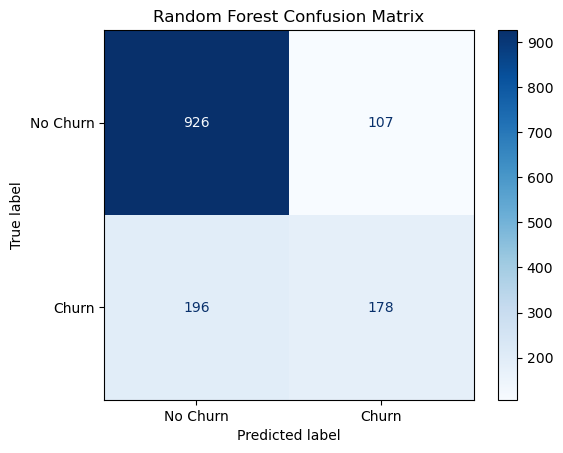

In [103]:
# Import confusion matrix tools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Display the confusion matrix values
print("Random Forest Confusion Matrix:")
print(cm_rf)

# Visualize the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest Confusion Matrix")
plt.show()

#  Train the XGBoost classifier

In [145]:

# Install XGBoost in the current Jupyter environment
%pip install xgboost --break-system-packages


# Calculate class imbalance weight
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative class count:", negative_count)
print("Positive class count:", positive_count)
print("Scale pos weight:", round(scale_pos_weight, 4))

# Initialize the XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train the XGBoost model
xgb_model.fit(X_train_processed, y_train)

print("\nXGBoost model trained successfully!")

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Negative class count: 4130
Positive class count: 1495
Scale pos weight: 2.7625

XGBoost model trained successfully!


In [112]:
# Import XGBoost after successful installation
from xgboost import XGBClassifier

# Verify the installed version
import xgboost

print("XGBoost version:", xgboost.__version__)
print("XGBClassifier imported successfully!")

XGBoost version: 3.2.0
XGBClassifier imported successfully!


# Train the XGBoost classifier

In [113]:
# Initialize the XGBoost classifier
xgb_model = XGBClassifier(
    n_estimators=300,        
    max_depth=4,             
    learning_rate=0.05,       
    subsample=0.8,            
    colsample_bytree=0.8,    
    scale_pos_weight=2.7625, 
    eval_metric="logloss",   
    random_state=42,          
    n_jobs=-1                 
)

# Train the XGBoost model
xgb_model.fit(X_train_processed, y_train)

# Confirm successful training
print("XGBoost model trained successfully!")

XGBoost model trained successfully!


#  Evaluate the XGBoost model

In [114]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predict churn labels
y_pred_xgb = xgb_model.predict(X_test_processed)

# Predict churn probabilities
y_prob_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]

# Calculate evaluation metrics
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)
xgb_roc_auc = roc_auc_score(y_test, y_prob_xgb)

# Display results
print("XGBoost Evaluation Results")
print("--------------------------------")
print(f"Accuracy:  {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall:    {xgb_recall:.4f}")
print(f"F1-Score:  {xgb_f1:.4f}")
print(f"ROC-AUC:   {xgb_roc_auc:.4f}")

XGBoost Evaluation Results
--------------------------------
Accuracy:  0.7328
Precision: 0.4983
Recall:    0.7754
F1-Score:  0.6067
ROC-AUC:   0.8300


#  Generate the XGBoost confusion matrix

XGBoost Confusion Matrix:
[[741 292]
 [ 84 290]]


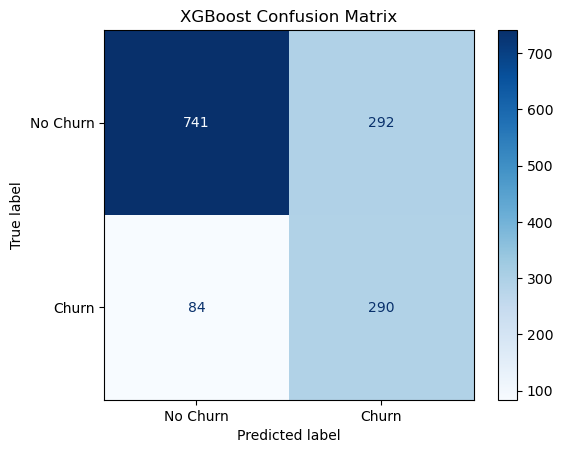

In [115]:
# Import confusion matrix visualization tools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the XGBoost confusion matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

# Display the confusion matrix values
print("XGBoost Confusion Matrix:")
print(cm_xgb)

# Visualize the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("XGBoost Confusion Matrix")
plt.show()

#  Compare both models in a performance table

In [116]:
# Create a comparison of Random Forest and XGBoost
model_comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Accuracy": [rf_accuracy, xgb_accuracy],
    "Precision": [rf_precision, xgb_precision],
    "Recall": [rf_recall, xgb_recall],
    "F1-Score": [rf_f1, xgb_f1],
    "ROC-AUC": [rf_roc_auc, xgb_roc_auc]
})

# Display the comparison table
model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7846,0.6246,0.4759,0.5402,0.8123
1,XGBoost,0.7328,0.4983,0.7754,0.6067,0.8300


#  Analyze XGBoost feature importance

Top 10 XGBoost Features:


,Feature,Importance
36,cat__Contract_Month-to-month,0.357476
16,cat__InternetService_Fiber optic,0.090519
27,cat__TechSupport_No,0.055195
18,cat__OnlineSecurity_No,0.051796
38,cat__Contract_Two year,0.039115
15,cat__InternetService_DSL,0.028296
19,cat__OnlineSecurity_No internet service,0.021946
35,cat__StreamingMovies_Yes,0.021718
43,cat__PaymentMethod_Electronic check,0.019215
32,cat__StreamingTV_Yes,0.017718


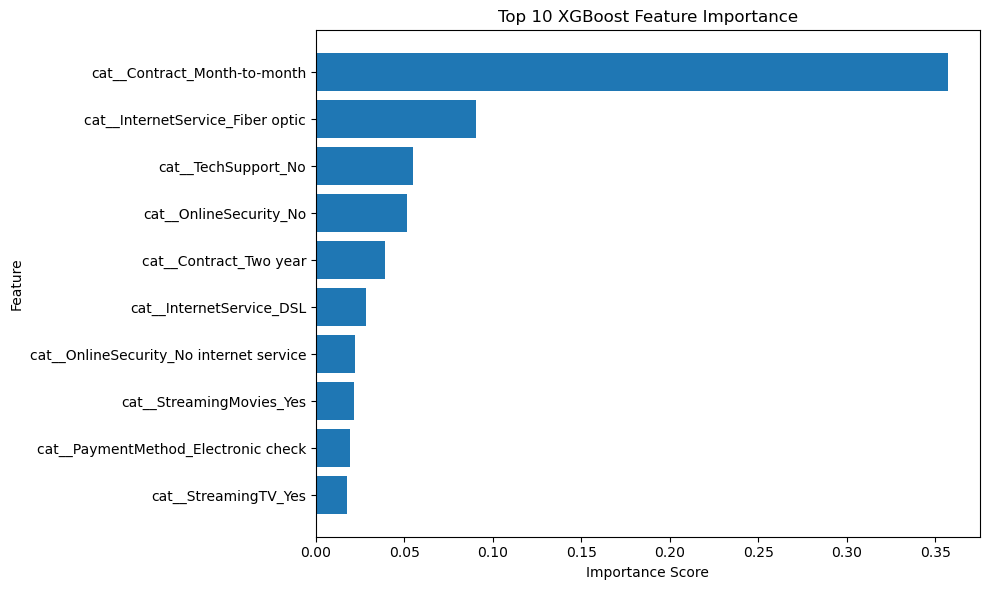

In [117]:
# Import visualization library
import matplotlib.pyplot as plt
import pandas as pd

# Get the encoded feature names from the preprocessing pipeline
feature_names = preprocessor.get_feature_names_out()

# Extract feature importance scores from XGBoost
importance_scores = xgb_model.feature_importances_

# Create a feature importance dataframe
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

# Sort features by importance in descending order
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Select the top 10 most important features
top_10_features = feature_importance.head(10)

# Display the top 10 features
print("Top 10 XGBoost Features:")
display(top_10_features)

# Visualize the top 10 features
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_features["Feature"],
    top_10_features["Importance"]
)

# Display the most important feature at the top
plt.gca().invert_yaxis()

plt.title("Top 10 XGBoost Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

#  Save the ROC curve plot

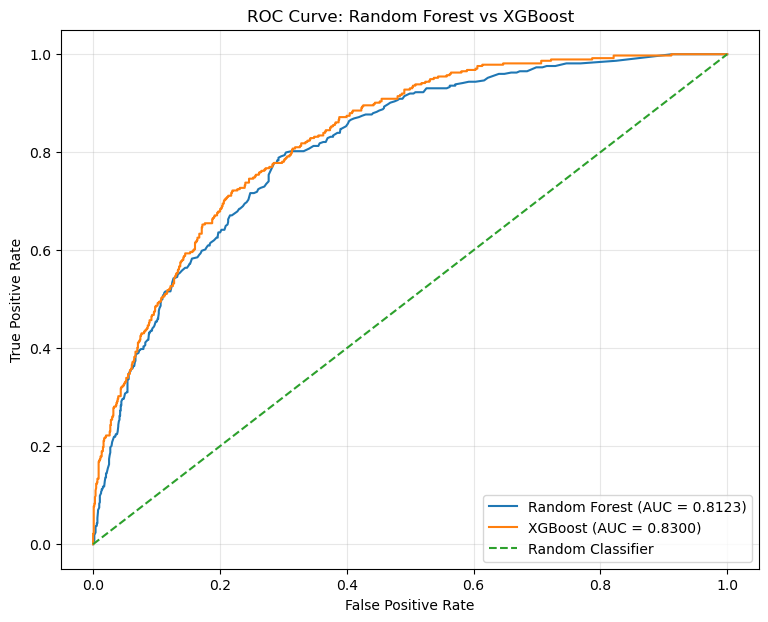

ROC curve saved successfully!


In [146]:
# Save the ROC curve plot as a high-resolution image

plt.figure(figsize=(9, 7))

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {roc_auc_rf:.4f})"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f"XGBoost (AUC = {roc_auc_xgb:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Random Forest vs XGBoost")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

# Save the figure
plt.savefig(
    "ROC_Curve_Model_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC curve saved successfully!")

# Save the feature importance plot

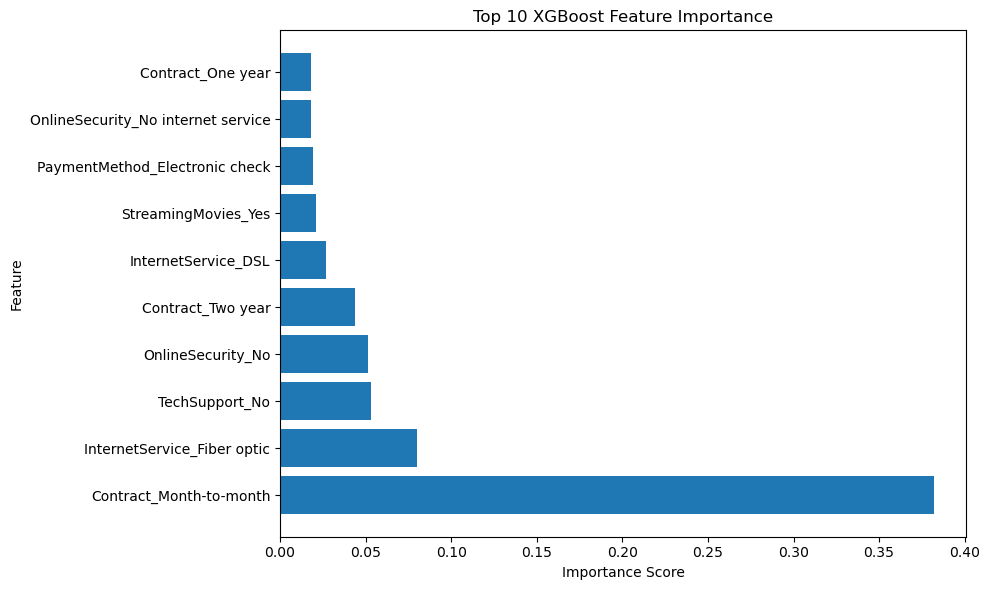

Feature importance plot saved successfully!


In [132]:
# Save the top 10 XGBoost feature importance plot

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_features["Feature"],
    top_10_features["Importance"]
)

# Put the most important feature at the top
plt.gca().invert_yaxis()

plt.title("Top 10 XGBoost Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()

# Save the figure at high resolution
plt.savefig(
    "XGBoost_Top10_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance plot saved successfully!")

#  Generate cross-validated probabilities

In [143]:
# Import cross-validation tools
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline

# Create a pipeline combining preprocessing and XGBoost
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=2.7625,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate cross-validated churn probabilities
y_train_cv_prob = cross_val_predict(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Confirm the result
print("Cross-validation completed successfully!")
print("Number of probabilities:", len(y_train_cv_prob))

Cross-validation completed successfully!
Number of probabilities: 5625


#  Find the best threshold for F1-score

In [134]:
# Import threshold evaluation metrics
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

# Define thresholds to evaluate
thresholds = np.arange(0.20, 0.71, 0.01)

# Store results
threshold_results = []

# Evaluate each threshold
for threshold in thresholds:

    # Convert probabilities into predicted classes
    y_train_cv_pred = (y_train_cv_prob >= threshold).astype(int)

    # Calculate evaluation metrics
    precision = precision_score(y_train, y_train_cv_pred)
    recall = recall_score(y_train, y_train_cv_pred)
    f1 = f1_score(y_train, y_train_cv_pred)

    # Save results
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

# Create a results dataframe
threshold_df = pd.DataFrame(threshold_results)

# Find the threshold with the highest F1-score
best_threshold_row = threshold_df.loc[
    threshold_df["F1-Score"].idxmax()
]

# Display the best threshold
print("Best Threshold for F1-Score Optimization")
print("---------------------------------------")
print(f"Threshold: {best_threshold_row['Threshold']:.2f}")
print(f"Precision: {best_threshold_row['Precision']:.4f}")
print(f"Recall:    {best_threshold_row['Recall']:.4f}")
print(f"F1-Score:  {best_threshold_row['F1-Score']:.4f}")

Best Threshold for F1-Score Optimization
---------------------------------------
Threshold: 0.55
Precision: 0.5623
Recall:    0.7271
F1-Score:  0.6342


#  Evaluate optimized XGBoost on the test set

In [147]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Use the optimized threshold
optimized_threshold = 0.55

# Convert test probabilities into predicted classes
y_pred_xgb_optimized = (
    y_prob_xgb >= optimized_threshold
).astype(int)

# Calculate optimized test metrics
xgb_opt_accuracy = accuracy_score(
    y_test, y_pred_xgb_optimized
)

xgb_opt_precision = precision_score(
    y_test, y_pred_xgb_optimized
)

xgb_opt_recall = recall_score(
    y_test, y_pred_xgb_optimized
)

xgb_opt_f1 = f1_score(
    y_test, y_pred_xgb_optimized
)

# ROC-AUC and PR-AUC use probability scores
xgb_opt_roc_auc = roc_auc_score(
    y_test, y_prob_xgb
)

xgb_opt_pr_auc = average_precision_score(
    y_test, y_prob_xgb
)

# Display results
print("Optimized XGBoost Test Results")
print("--------------------------------")
print(f"Threshold:  {optimized_threshold:.2f}")
print(f"Accuracy:   {xgb_opt_accuracy:.4f}")
print(f"Precision:  {xgb_opt_precision:.4f}")
print(f"Recall:     {xgb_opt_recall:.4f}")
print(f"F1-Score:   {xgb_opt_f1:.4f}")
print(f"ROC-AUC:    {xgb_opt_roc_auc:.4f}")
print(f"PR-AUC:     {xgb_opt_pr_auc:.4f}")

Optimized XGBoost Test Results
--------------------------------
Threshold:  0.55
Accuracy:   0.7498
Precision:  0.5205
Recall:     0.7460
F1-Score:   0.6132
ROC-AUC:    0.8300
PR-AUC:     0.6451


#  Generate the optimized XGBoost confusion matrix

Optimized XGBoost Confusion Matrix:
[[776 257]
 [ 95 279]]


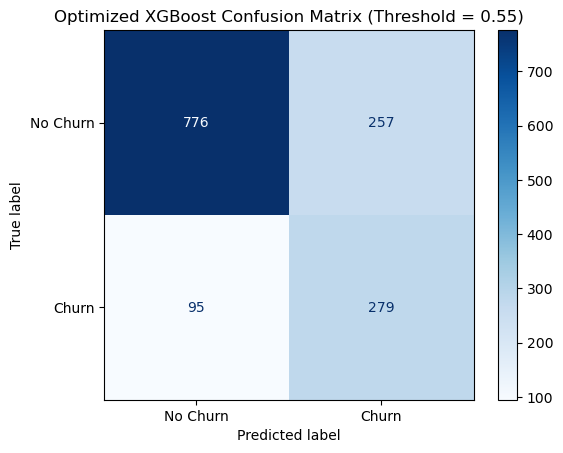

In [148]:
# Import confusion matrix tools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the confusion matrix using optimized predictions
cm_xgb_optimized = confusion_matrix(
    y_test,
    y_pred_xgb_optimized
)

# Display the confusion matrix values
print("Optimized XGBoost Confusion Matrix:")
print(cm_xgb_optimized)

# Visualize the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb_optimized,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Optimized XGBoost Confusion Matrix (Threshold = 0.55)")
plt.show()

#  Calculate Specificity and NPV

In [138]:
tn, fp, fn, tp = cm_xgb_optimized.ravel()

specificity_xgb_optimized = tn / (tn + fp)
npv_xgb_optimized = tn / (tn + fn)

print("Optimized XGBoost - Additional Metrics")
print("-------------------------------------")
print(f"Specificity: {specificity_xgb_optimized:.4f}")
print(f"NPV:         {npv_xgb_optimized:.4f}")

Optimized XGBoost - Additional Metrics
-------------------------------------
Specificity: 0.7512
NPV:         0.8909


# Final optimized XGBoost evaluation

In [149]:
# Final evaluation metrics for optimized XGBoost

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd

xgb_optimized_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall (Sensitivity)",
        "Specificity",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC",
        "Negative Predictive Value (NPV)"
    ],
    "Optimized XGBoost": [
        accuracy_score(y_test, y_pred_xgb_optimized),
        precision_score(y_test, y_pred_xgb_optimized),
        recall_score(y_test, y_pred_xgb_optimized),
        specificity_xgb_optimized,
        f1_score(y_test, y_pred_xgb_optimized),
        roc_auc_score(y_test, y_prob_xgb),
        average_precision_score(y_test, y_prob_xgb),
        npv_xgb_optimized
    ]
})

xgb_optimized_results["Optimized XGBoost"] = (
    xgb_optimized_results["Optimized XGBoost"].round(4)
)

print("Final Optimized XGBoost Evaluation")
display(xgb_optimized_results)

Final Optimized XGBoost Evaluation


,Metric,Optimized XGBoost
0,Accuracy,0.7498
1,Precision,0.5205
2,Recall (Sensitivity),0.7460
3,Specificity,0.7512
4,F1-Score,0.6132
5,ROC-AUC,0.8300
6,PR-AUC,0.6451
7,Negative Predictive Value (NPV),0.8909


#  Compare Random Forest and Optimized XGBoost

In [140]:
# Step 58: Compare Random Forest and Optimized XGBoost

model_comparison_final = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall (Sensitivity)",
        "Specificity",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC",
        "NPV"
    ],
    "Random Forest": [
        0.7846,
        0.6246,
        0.4759,
        0.8964,
        0.5402,
        0.8123,
        average_precision_score(y_test, y_prob_rf),
        0.8254
    ],
    "Optimized XGBoost": [
        0.7498,
        0.5205,
        0.7460,
        0.7512,
        0.6132,
        0.8300,
        0.6451,
        0.8909
    ]
})

model_comparison_final.iloc[:, 1:] = (
    model_comparison_final.iloc[:, 1:].round(4)
)

print("Final Model Comparison")
display(model_comparison_final)

Final Model Comparison


,Metric,Random Forest,Optimized XGBoost
0,Accuracy,0.7846,0.7498
1,Precision,0.6246,0.5205
2,Recall (Sensitivity),0.4759,0.7460
3,Specificity,0.8964,0.7512
4,F1-Score,0.5402,0.6132
5,ROC-AUC,0.8123,0.8300
6,PR-AUC,0.5881,0.6451
7,NPV,0.8254,0.8909


# Step 59 — Visualize Final Model Comparison

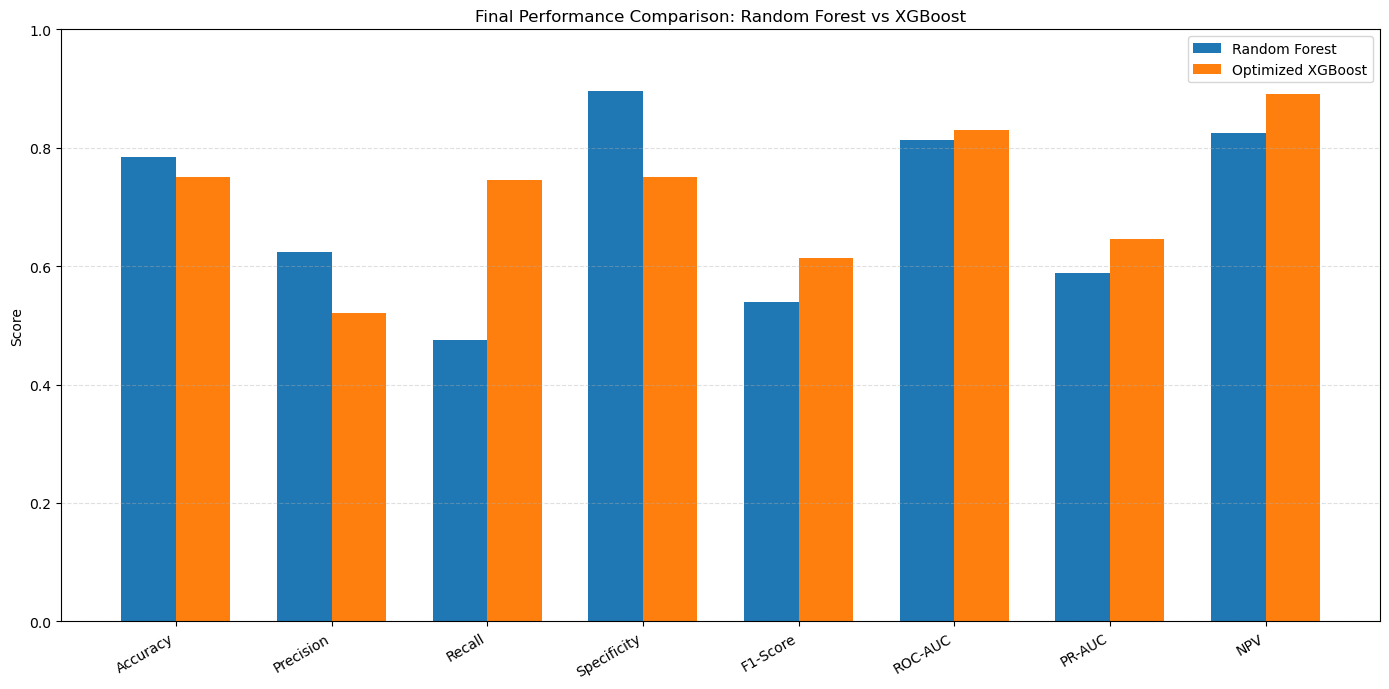

In [141]:
# Step 59: Visual comparison of Random Forest and XGBoost

import matplotlib.pyplot as plt
import numpy as np

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC",
    "NPV"
]

rf_scores = model_comparison_final["Random Forest"].values
xgb_scores = model_comparison_final["Optimized XGBoost"].values

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(14, 7))

plt.bar(x - width/2, rf_scores, width, label="Random Forest")
plt.bar(x + width/2, xgb_scores, width, label="Optimized XGBoost")

plt.xticks(x, metrics, rotation=30, ha="right")
plt.ylabel("Score")
plt.title("Final Performance Comparison: Random Forest vs XGBoost")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "Final_Model_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Analyze the Business Impact of Churn Predictions

In [142]:
# Step 60: Business Impact Analysis

tn, fp, fn, tp = cm_xgb_optimized.ravel()

total_customers = len(y_test)

correctly_identified_churners = tp
unnecessary_retention_targets = fp
missed_churners = fn
correctly_identified_retained = tn

print("Business Impact Analysis - Optimized XGBoost")
print("-------------------------------------------")

print(f"Total test customers: {total_customers}")
print(f"Correctly identified churners: {tp}")
print(f"Unnecessary retention targets: {fp}")
print(f"Missed churners: {fn}")
print(f"Correctly identified retained customers: {tn}")

print(f"\nChurners identified: {tp / (tp + fn) * 100:.2f}%")
print(f"False positive rate: {fp / (fp + tn) * 100:.2f}%")
print(f"Customers flagged for retention: {(tp + fp) / total_customers * 100:.2f}%")

Business Impact Analysis - Optimized XGBoost
-------------------------------------------
Total test customers: 1407
Correctly identified churners: 279
Unnecessary retention targets: 257
Missed churners: 95
Correctly identified retained customers: 776

Churners identified: 74.60%
False positive rate: 24.88%
Customers flagged for retention: 38.10%
